# Torus Blob Generation Demo

This notebook demonstrates the usage of the `TorusBlobSampler` class from the SynthShapes library.
We'll generate torus-shaped blobs with various parameters and visualize them using 3D slices.

## Setup and Imports

In [1]:
import torch
import matplotlib.pyplot as plt
import numpy as np
from SynthShapes.shapes import TorusBlobSampler
import cornucopia as cc

# Set device
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f"Using device: {device}")

Using device: cpu


## Helper Function for Visualization

In [41]:
def visualize_torus_slices(labels, mask=None, title="Torus Blobs"):
    """
    Visualize 3D torus blobs by showing orthogonal slices.

    Parameters
    ----------
    labels : torch.Tensor
        3D tensor with torus labels (1, D, H, W) or (D, H, W)
    mask : torch.Tensor, optional
        Binary mask of torus regions
    title : str
        Title for the figure
    """
    # Remove batch dimension if present
    if labels.ndim == 4:
        labels = labels.squeeze(0)

    # Convert to numpy and move to CPU
    labels_np = labels.cpu().numpy()

    # Get middle slices
    d, h, w = labels_np.shape
    mid_d, mid_h, mid_w = d // 2, h // 2, w // 2

    # Create figure with three subplots
    fig, axes = plt.subplots(1, 3, figsize=(15, 5))

    # Axial slice (depth)
    axes[0].imshow(labels_np[mid_d, :, :], cmap='nipy_spectral', interpolation='nearest')
    axes[0].set_title(f'Axial Slice (depth={mid_d})')
    axes[0].axis('off')

    # Coronal slice (height)
    axes[1].imshow(labels_np[:, mid_h, :], cmap='nipy_spectral', interpolation='nearest')
    axes[1].set_title(f'Coronal Slice (height={mid_h})')
    axes[1].axis('off')

    # Sagittal slice (width)
    axes[2].imshow(labels_np[:, :, mid_w], cmap='nipy_spectral', interpolation='nearest')
    axes[2].set_title(f'Sagittal Slice (width={mid_w})')
    axes[2].axis('off')

    plt.suptitle(title, fontsize=16, fontweight='bold')
    plt.tight_layout()
    plt.show()

    # Print statistics
    n_tori = int(labels_np.max())
    n_voxels = int((labels_np > 0).sum())
    print(f"Generated {n_tori} torus blobs")
    print(f"Total voxels occupied: {n_voxels}")
    print(f"Volume fraction: {n_voxels / labels_np.size * 100:.2f}%")

## 3D Visualization Helper Functions

These functions provide lightweight 3D visualizations suitable for CPU rendering:

In [43]:
from mpl_toolkits.mplot3d import Axes3D
from scipy import ndimage

def extract_surface_voxels(volume, downsample=2):
    """
    Extract only surface voxels from a 3D volume for lightweight visualization.
    
    Parameters
    ----------
    volume : np.ndarray
        3D binary or labeled volume
    downsample : int
        Factor to downsample the volume (helps performance on CPU)
    
    Returns
    -------
    coords : tuple of arrays
        (z, y, x) coordinates of surface voxels
    values : np.ndarray
        Label values at surface voxels
    """
    # Downsample if requested
    if downsample > 1:
        volume = volume[::downsample, ::downsample, ::downsample]
    
    # Find surface voxels by erosion
    binary = volume > 0
    eroded = ndimage.binary_erosion(binary, structure=np.ones((3, 3, 3)))
    surface = binary & ~eroded
    
    # Get coordinates of surface voxels
    coords = np.where(surface)
    values = volume[coords]
    
    return coords, values


def visualize_3d_surface(labels, title="3D Torus Visualization", downsample=2, figsize=(10, 8)):
    """
    Visualize 3D torus blobs using matplotlib 3D scatter plot of surface voxels.
    
    Parameters
    ----------
    labels : torch.Tensor or np.ndarray
        3D tensor with torus labels
    title : str
        Title for the figure
    downsample : int
        Downsampling factor (higher = faster but lower quality)
    figsize : tuple
        Figure size
    """
    # Convert to numpy if needed
    if isinstance(labels, torch.Tensor):
        labels = labels.squeeze().cpu().numpy()
    
    # Extract surface voxels
    coords, values = extract_surface_voxels(labels, downsample=downsample)
    
    # Create 3D plot
    fig = plt.figure(figsize=figsize)
    ax = fig.add_subplot(111, projection='3d')
    
    # Plot surface voxels colored by label
    scatter = ax.scatter(coords[2], coords[1], coords[0], 
                        c=values, cmap='nipy_spectral',
                        marker='s', s=20, alpha=0.6)
    
    ax.set_xlabel('X')
    ax.set_ylabel('Y')
    ax.set_zlabel('Z')
    ax.set_title(title)
    
    # Add colorbar
    plt.colorbar(scatter, ax=ax, label='Torus ID', shrink=0.5)
    
    # Equal aspect ratio
    max_range = labels.shape[0] // downsample
    ax.set_xlim([0, max_range])
    ax.set_ylim([0, max_range])
    ax.set_zlim([0, max_range])
    
    plt.tight_layout()
    plt.show()
    
    print(f"Rendered {len(coords[0])} surface voxels (downsampled by {downsample}x)")


def visualize_3d_voxels(labels, title="3D Torus Voxels", max_voxels=10000):
    """
    Visualize using matplotlib's voxel plot (good for sparse data only).
    
    Parameters
    ----------
    labels : torch.Tensor or np.ndarray
        3D tensor with torus labels
    title : str
        Title for the figure
    max_voxels : int
        Maximum number of voxels to render (automatically downsamples if exceeded)
    """
    # Convert to numpy if needed
    if isinstance(labels, torch.Tensor):
        labels = labels.squeeze().cpu().numpy()
    
    # Check if we need to downsample
    n_voxels = (labels > 0).sum()
    downsample = max(1, int(np.ceil((n_voxels / max_voxels) ** (1/3))))
    
    if downsample > 1:
        labels = labels[::downsample, ::downsample, ::downsample]
        print(f"Downsampled by {downsample}x to keep voxel count manageable")
    
    # Create binary mask
    filled = labels > 0
    
    # Create color array
    colors = np.zeros(labels.shape + (4,))  # RGBA
    
    # Assign colors based on labels
    unique_labels = np.unique(labels[labels > 0])
    cmap = plt.cm.nipy_spectral
    
    for i, label_id in enumerate(unique_labels):
        mask = labels == label_id
        color = cmap(i / len(unique_labels))
        colors[mask] = color
    
    # Create 3D plot
    fig = plt.figure(figsize=(10, 8))
    ax = fig.add_subplot(111, projection='3d')
    
    # Plot voxels
    ax.voxels(filled, facecolors=colors, edgecolor='k', alpha=0.7, linewidth=0.1)
    
    ax.set_xlabel('X')
    ax.set_ylabel('Y')
    ax.set_zlabel('Z')
    ax.set_title(title)
    
    plt.tight_layout()
    plt.show()

## Example 1: Basic Torus Generation

Generate torus blobs with default parameters

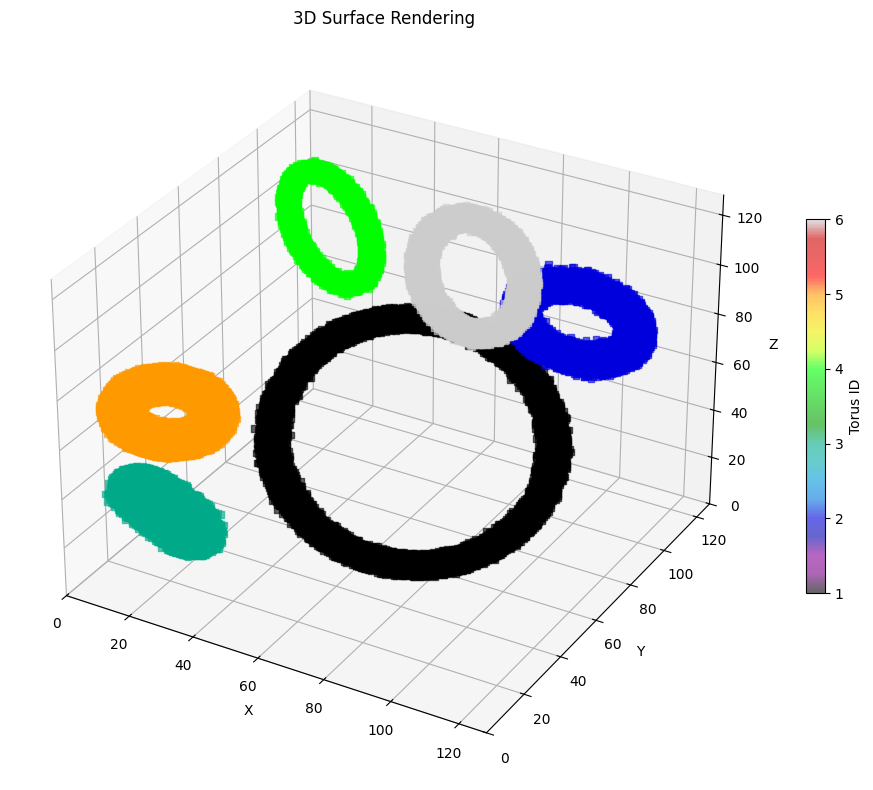

Rendered 27451 surface voxels (downsampled by 1x)


In [44]:
# Create sampler with default parameters
torus_sampler_basic = TorusBlobSampler(
    major_radius_range=[10, 40],
    minor_radius_range=[3, 6],
    n_blobs=cc.RandInt(5, 20),
    jitter=cc.Uniform(0, 0.5),
    device=device,
    shape=128,
    return_mask=True
)

# Generate torus blobs
labels_basic, mask_basic = torus_sampler_basic()

# Visualize the basic torus generation in 3D
# Method 1: Surface voxel rendering (faster, good for most cases)
visualize_3d_surface(labels_basic, title="3D Surface Rendering", downsample=1)

# Method 2: Full voxel rendering (slower but shows complete structure)
# Uncomment to try this method:
# visualize_3d_voxels(labels_basic, title="3D Voxel Rendering", max_voxels=5000)

## Example 2: Small Tori with High Jitter

Generate many small tori with high noise for irregular shapes

Downsampled by 2x to keep voxel count manageable


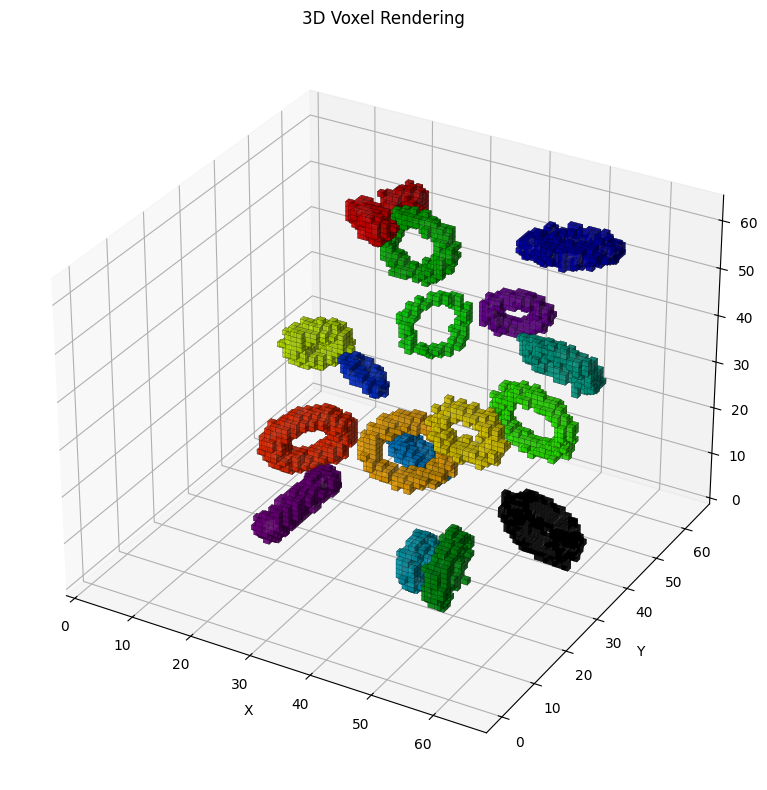

In [ ]:
# Create sampler with smaller radii and more jitter
torus_sampler_small = TorusBlobSampler(
    major_radius_range=[5, 12],
    minor_radius_range=[2, 4],
    n_blobs=cc.RandInt(15, 25),
    jitter=cc.Uniform(0.3, 0.8),
    device=device,
    shape=128,
    return_mask=True
)

# Generate torus blobs
labels_small, mask_small = torus_sampler_small()

# Visualie (with voxel function)
visualize_3d_voxels(labels_small, title="3D Voxel Rendering", max_voxels=5000)

## Example 3: Analyzing the Binary Mask

Demonstrate the binary mask output and overlay it on labels

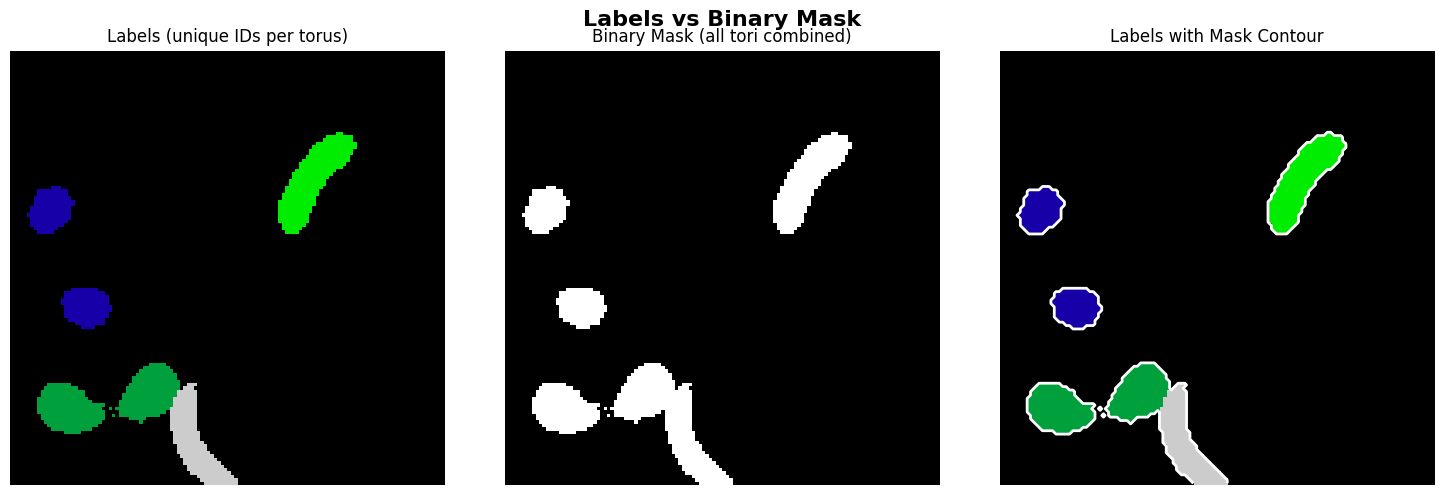

In [33]:
# Generate torus blobs with mask
torus_sampler_mask = TorusBlobSampler(
    major_radius_range=[12, 18],
    minor_radius_range=[4, 7],
    n_blobs=cc.RandInt(6, 12),
    jitter=cc.Uniform(0, 0.3),
    device=device,
    shape=128,
    return_mask=True
)

labels_mask, mask = torus_sampler_mask()

# Convert to numpy
labels_np = labels_mask.squeeze(0).cpu().numpy()
mask_np = mask.squeeze(0).cpu().numpy()

# Get middle slice
mid_d = labels_np.shape[0] // 2

# Create comparison figure
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# Labels only
axes[0].imshow(labels_np[mid_d, :, :], cmap='nipy_spectral', interpolation='nearest')
axes[0].set_title('Labels (unique IDs per torus)')
axes[0].axis('off')

# Binary mask only
axes[1].imshow(mask_np[mid_d, :, :], cmap='gray', interpolation='nearest')
axes[1].set_title('Binary Mask (all tori combined)')
axes[1].axis('off')

# Overlay
axes[2].imshow(labels_np[mid_d, :, :], cmap='nipy_spectral', interpolation='nearest')
axes[2].contour(mask_np[mid_d, :, :], levels=[0.5], colors='white', linewidths=2)
axes[2].set_title('Labels with Mask Contour')
axes[2].axis('off')

plt.suptitle('Labels vs Binary Mask', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

## Example 4: Interactive 3D Visualization with Plotly (Optional)

If you have plotly installed, you can create interactive 3D visualizations that allow rotation and zooming

In [45]:
# !pip install plotly

In [62]:
try:
    import plotly.graph_objects as go
    
    # Generate a simple torus sample for interactive visualization
    torus_sampler_interactive = TorusBlobSampler(
        major_radius_range=[10, 20],
        minor_radius_range=[2, 4],
        n_blobs=cc.Fixed(5),
        jitter=cc.Fixed(0.2),
        device=device,
        shape=128,
        return_mask=False
    )
    
    labels_interactive = torus_sampler_interactive().squeeze().cpu().numpy()
    
    # Extract surface voxels (downsampled for performance)
    coords, values = extract_surface_voxels(labels_interactive, downsample=1)
    
    # Create plotly 3D scatter plot
    fig = go.Figure(data=[go.Scatter3d(
        x=coords[2],
        y=coords[1],
        z=coords[0],
        mode='markers',
        marker=dict(
            size=5,
            color=values,
            # colorscale='Viridis',
            colorscale='turbo',
            showscale=True,
            colorbar=dict(title="Torus ID"),
            opacity=1
        )
    )])
    
    fig.update_layout(
        title="Interactive 3D Torus Visualization (drag to rotate)",
        scene=dict(
            xaxis_title='X',
            yaxis_title='Y',
            zaxis_title='Z',
            aspectmode='cube'
        ),
        width=800,
        height=800
    )
    
    fig.show()
    
    print("Interactive plot ready! Use your mouse to rotate, zoom, and pan.")
    
except ImportError:
    print("Plotly not installed. To use interactive 3D visualization, install it with:")
    print("  uv pip install plotly")

Interactive plot ready! Use your mouse to rotate, zoom, and pan.
